In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik

In [3]:
df = pd.read_csv("./fraudTrain.csv")
df_test = pd.read_csv("./fraudTest.csv")

In [4]:
pd.set_option('display.max_columns', None)

In [5]:
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [6]:
df.describe()

,Unnamed: 0,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,6.483370e+05,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,3.743180e+05,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,0.000000e+00,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,3.241685e+05,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,6.483370e+05,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,9.725055e+05,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,1.296674e+06,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


In [7]:
df.shape

(1296675, 23)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  str    
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  str    
 4   category               1296675 non-null  str    
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  str    
 7   last                   1296675 non-null  str    
 8   gender                 1296675 non-null  str    
 9   street                 1296675 non-null  str    
 10  city                   1296675 non-null  str    
 11  state                  1296675 non-null  str    
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long                   129667

In [9]:
df.isna().sum()

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

In [10]:
df.isnull().sum()

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

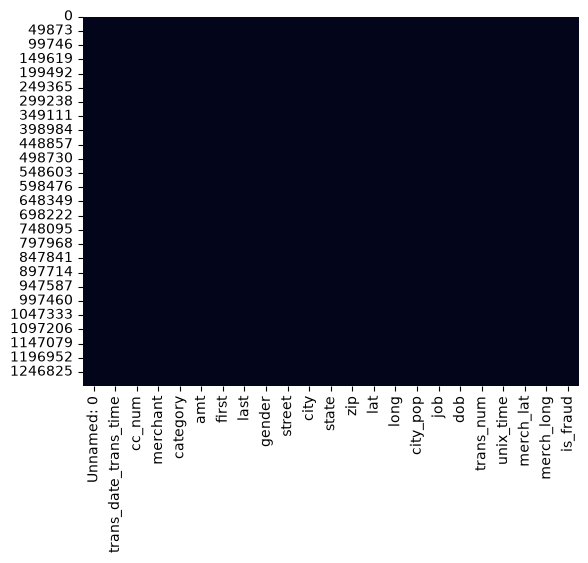

In [11]:
sns.heatmap(df.isnull(), cbar=False);

Значения есть все, большое количеств признаков - строковые значения, так же есть datetime, который необходимо будет преобразовывать. Есть небольшие проблемы с признаком даты, время, по unixytime признакоу получается 2012, по trans_date_trans_time - 2019, далее время будет преобразовано так, чтобы дате и времени были назначены числовые признаки, дата будет взята из trans_date_trans_time, а время из Unixtime. Так же преобразования требует и признак dob

In [12]:
df[df.columns].nunique()

Unnamed: 0               1296675
trans_date_trans_time    1274791
cc_num                       983
merchant                     693
category                      14
amt                        52928
first                        352
last                         481
gender                         2
street                       983
city                         894
state                         51
zip                          970
lat                          968
long                         969
city_pop                     879
job                          494
dob                          968
trans_num                1296675
unix_time                1274823
merch_lat                1247805
merch_long               1275745
is_fraud                       2
dtype: int64

In [13]:
cat = ["cc_num", "merchant", "category", "first", "last", "gender", "street", "city", "state", "zip", "job", "is_fraud"]
num = ["trans_date_trans_time", "amt", "first", "last", "lat", "long", "city_pop", "dob", "trans_num", "unix_time", "merch_lat", "merch_long"]

<Axes: xlabel='lat', ylabel='long'>

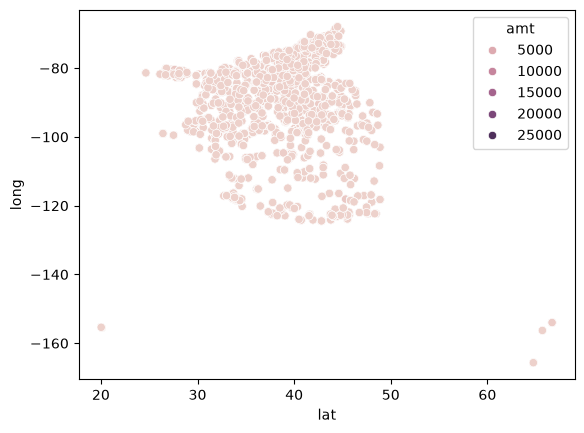

In [14]:
sns.scatterplot(df, x = df["lat"], y= df["long"], hue = "amt")

<Axes: xlabel='lat', ylabel='long'>

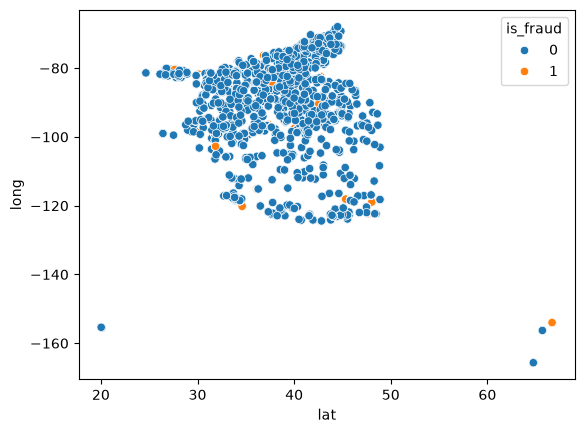

In [15]:
sns.scatterplot(df, x = df["lat"], y= df["long"], hue = "is_fraud")

Разброс по территории для таргета достаточно высокий, особенных сосрдеточений не выявил, использования агрегационного признака, с выделением регионов (как для регрессии), может быть пагубно повлиять, в области Гавай такой регион может сгенерировать необоснованную инфомрацию о таргете, так как данных там не много

In [14]:
len(df[df["long"] < -140]["city"])

4679

In [15]:
df[df["long"] < -140]["city"].unique()

<ArrowStringArray>
['Honokaa', 'Wales', 'Paauilo', 'Huslia', 'Kaktovik']
Length: 5, dtype: str

Присутсвутют значения, выбросы, но значения не фиктивные, города являются территориями Аляски и Гавай, расположенных на удалении от основной территории

array([[<Axes: title={'center': 'amt'}>, <Axes: title={'center': 'lat'}>,
        <Axes: title={'center': 'long'}>],
       [<Axes: title={'center': 'city_pop'}>,
        <Axes: title={'center': 'unix_time'}>,
        <Axes: title={'center': 'merch_lat'}>],
       [<Axes: title={'center': 'merch_long'}>, <Axes: >, <Axes: >]],
      dtype=object)

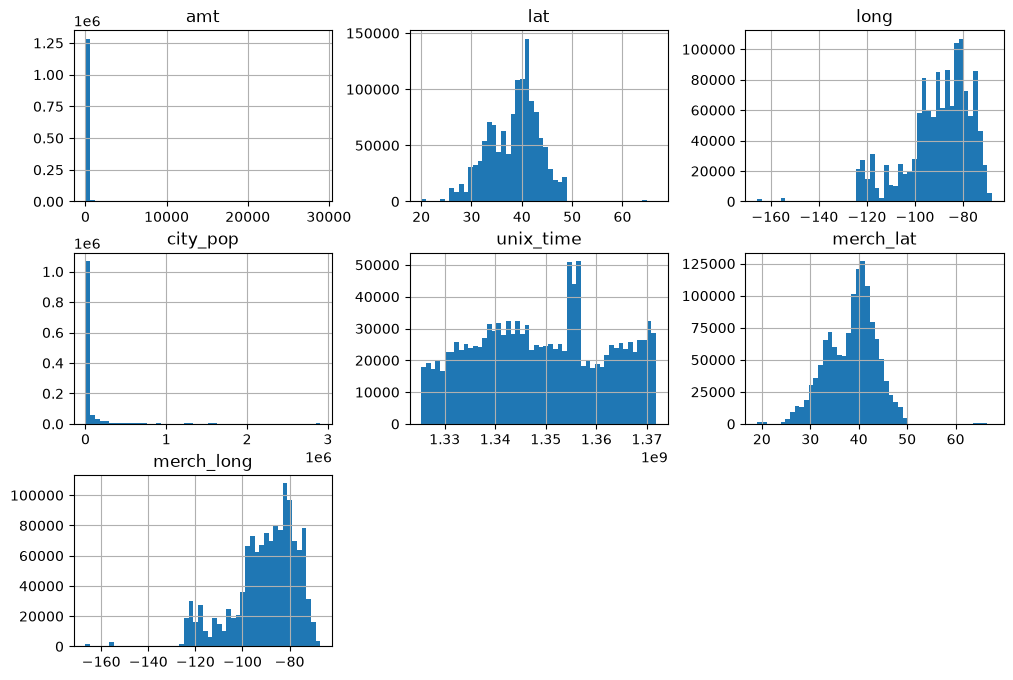

In [16]:
num_cols_scat = ["amt", "first", "last", "lat", "long", "city_pop", "dob", "unix_time", "merch_lat", "merch_long"]
df[num_cols_scat].hist(bins = 50, figsize = (12, 8))

Нормальных распределений тут откровенно говоря не много, что касается Значений amoun и city population, надо разбираться с ними поподробнее, так как значения на графике выглядят достаточно странно

In [17]:
print(df["amt"].quantile(0.25))
print(df["amt"].quantile(0.75))
print(max(df["amt"]))

9.65
83.14
28948.9


In [18]:
print(df["city_pop"].quantile(0.25))
print(df["city_pop"].quantile(0.75))
print(max(df["city_pop"]))

743.0
20328.0
2906700


Судя по квантилям, для этих двух групп сущестуют выбросы, которые учитываются в гистгорамме, далее буду 

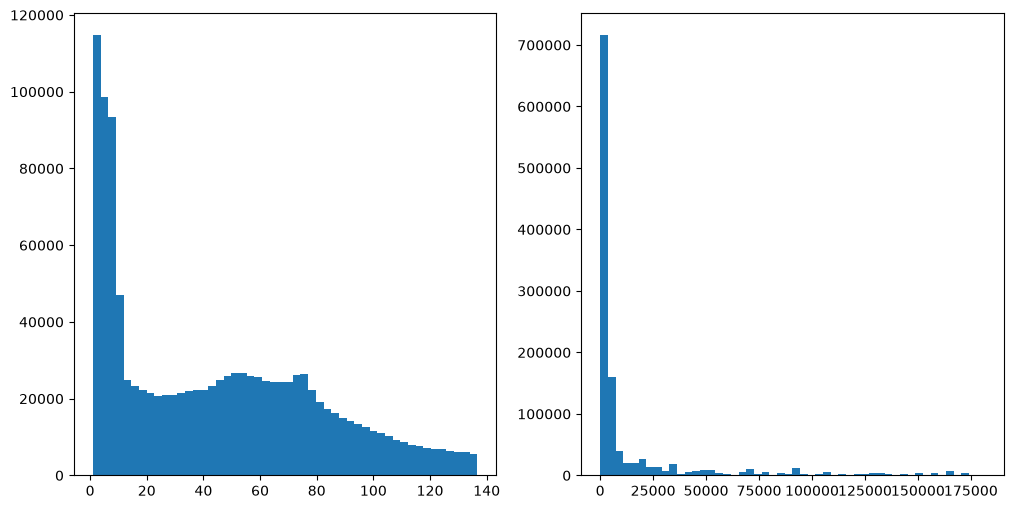

In [19]:
fig, ax = plt.subplots(nrows = 1, ncols = 2,  figsize=(12, 6))
ax[0].hist(df[df["amt"] < df["amt"].quantile(0.90)]["amt"], bins = 50)
ax[1].hist(df[df["city_pop"] < df["city_pop"].quantile(0.90)]["city_pop"], bins = 50);

Большая часть значений все равно сосредоточена в первых нескольких бинах, для линейных моделей это может быть критично

<Axes: xlabel='is_fraud', ylabel='count'>

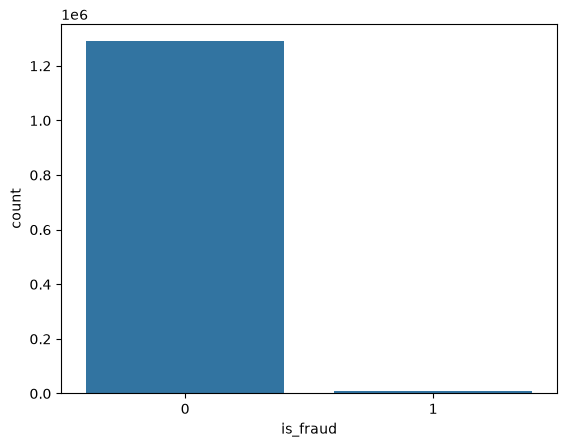

In [20]:
sns.countplot(df, x="is_fraud")

Присутствует явный дисбаланс класса и в датасете присутствует признак времени, нужно будет подумать, как делить датасет, так как в обучающую выборку должны будут попасть семпл минорного класса и учитываться разделение на временные ряд

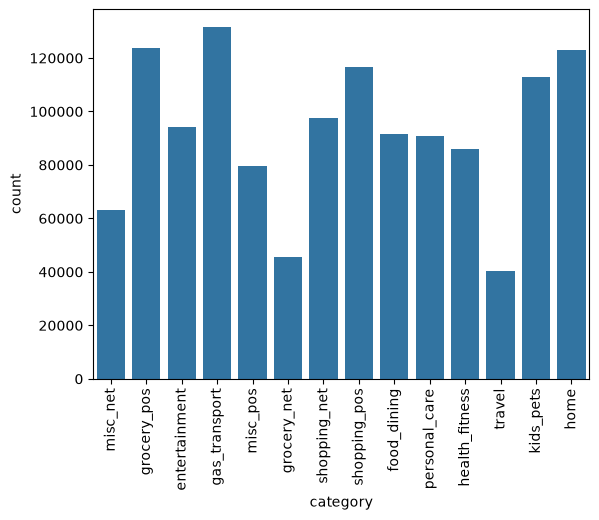

In [21]:
sns.countplot(df, x="category")
plt.xticks(rotation=90);

<Axes: xlabel='gender', ylabel='count'>

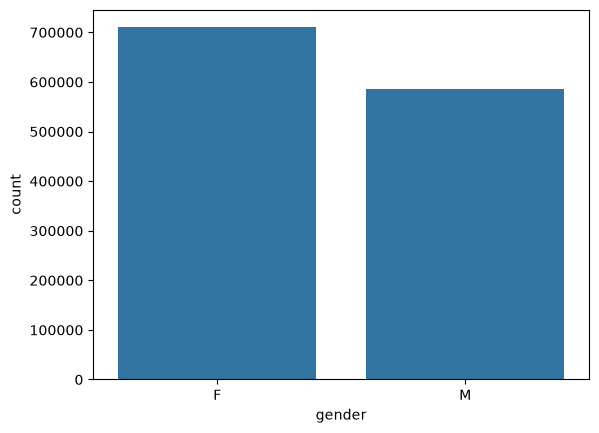

In [22]:
sns.countplot(df, x = "gender")

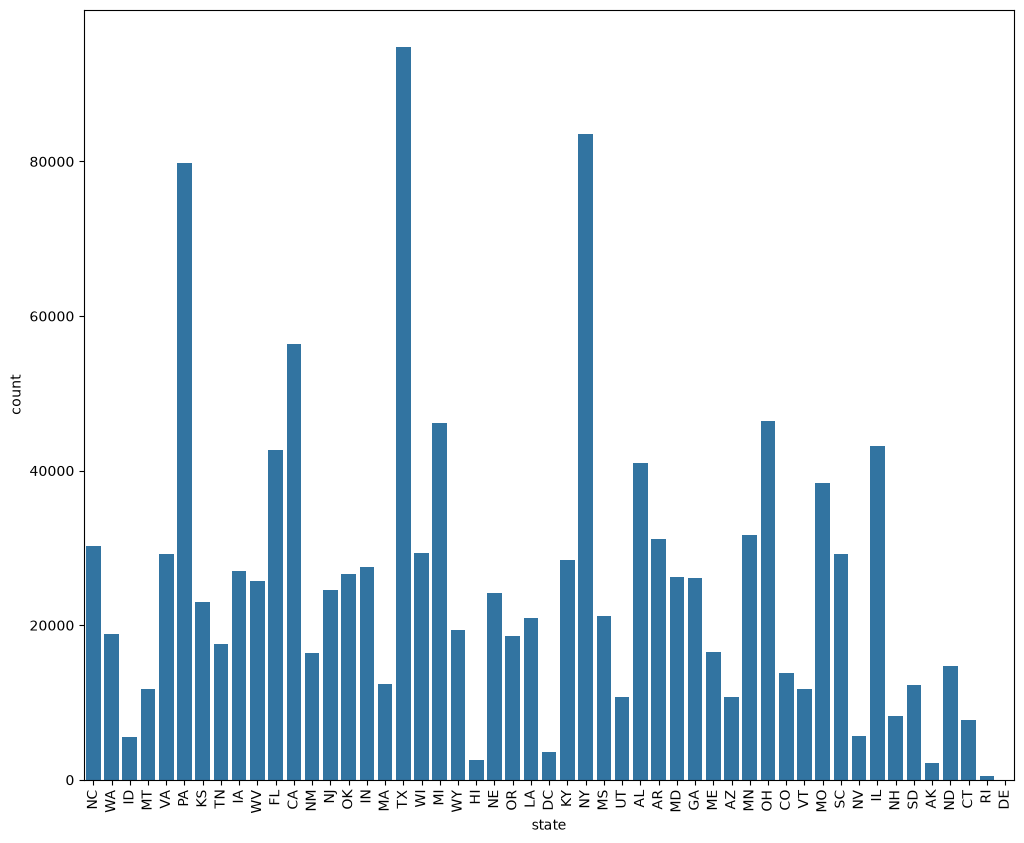

In [23]:
plt.figure(figsize = (12, 10))
sns.countplot(df, x = "state")
plt.xticks(rotation=90);

Очевидно лидерами по транзакциям являются штаты New york, Texas и... Pensylavania

<Axes: xlabel='unix_time', ylabel='amt'>

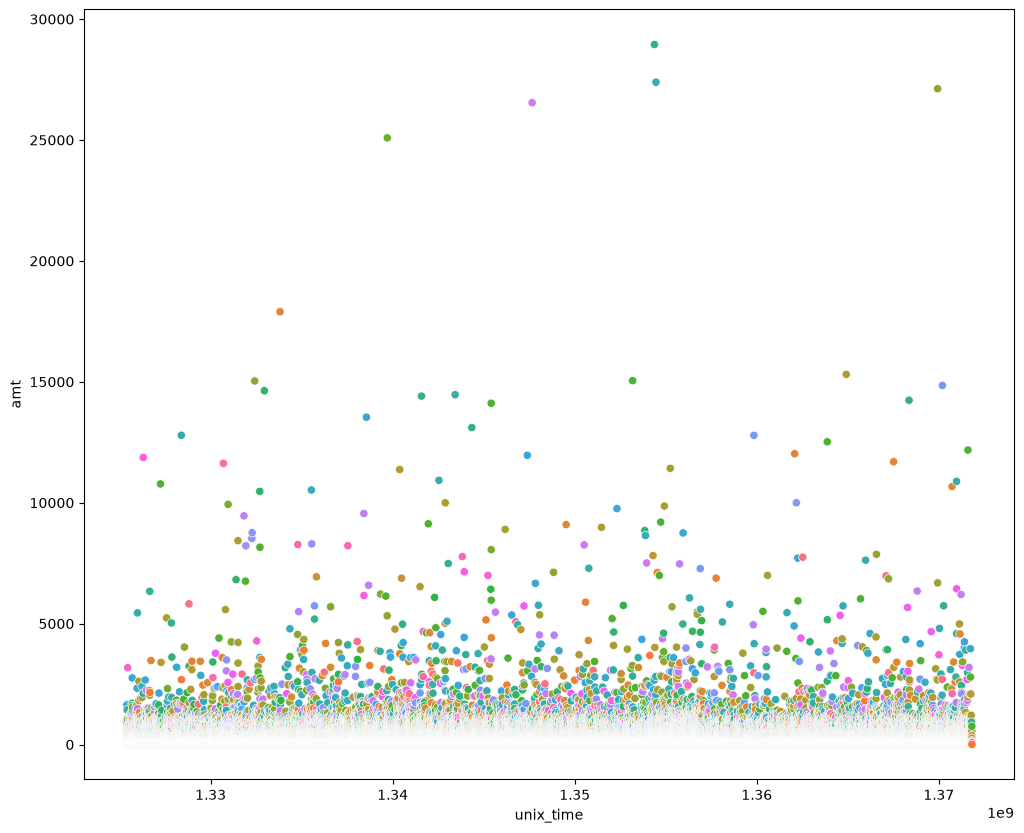

In [24]:
plt.figure(figsize = (12,10))
sns.scatterplot(df, x="unix_time", y = "amt", hue ="state", legend = False)

In [34]:
corr_matrix = df.drop(["cc_num", "zip", "trans_num", "trans_date_trans_time"], axis =1 ).phik_matrix()

interval columns not set, guessing: ['Unnamed: 0', 'amt', 'lat', 'long', 'city_pop', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']


<Axes: >

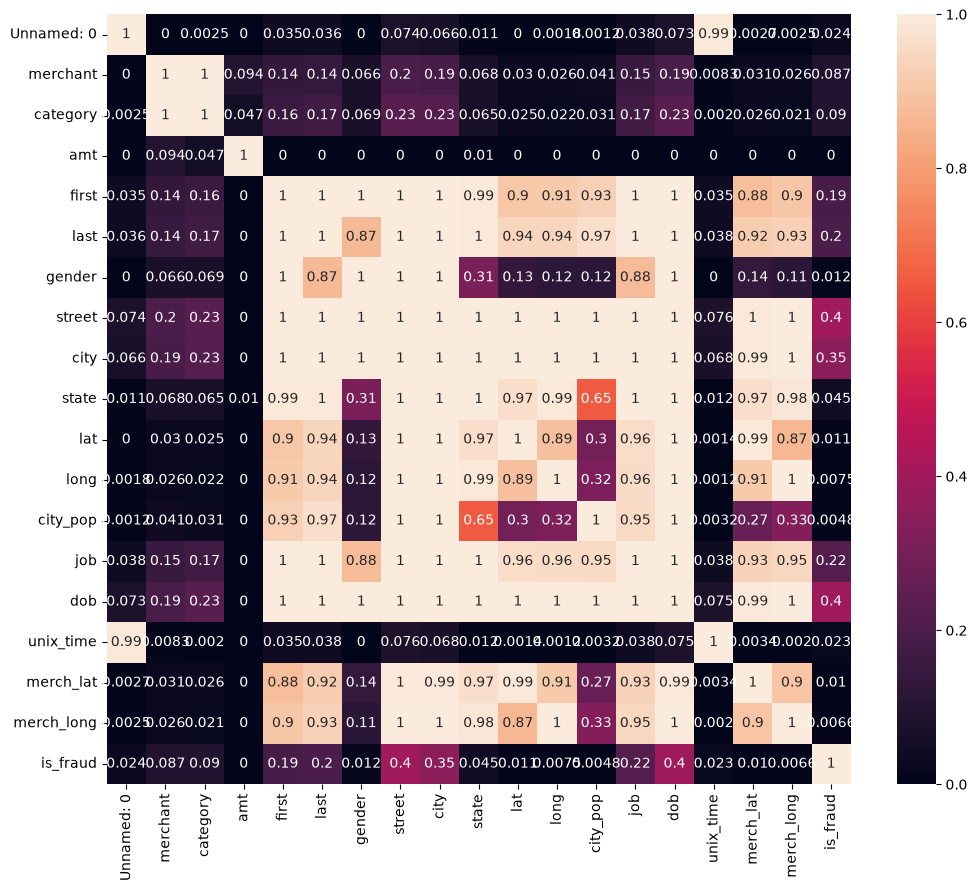

In [38]:
plt.figure(figsize = (12,10))
sns.heatmap(corr_matrix, annot=True)

In [41]:
df["full_name"] = df["first"] + df["last"] 
df["full_name"].nunique()

973

In [44]:
df["dob"].nunique()

968

In [45]:
print(max(df["dob"]), min(df["dob"]))

2005-01-29 1924-10-30


Действительно, как бы не было странно, получается, что для признаков может сущетсвовать прямая корреляция, так как на дистанции аж в 81 год, при схожем количестве уникальных значений получается что максимальное количество повторения даты рождения может быть всего - 5.

In [51]:
df["city"].nunique()

894

In [52]:
df["street"].nunique()

983

Так же примерно отсюда вывод, что при значений в 973 уникальных записей имя/фамилия и уникальных записей города - 894, происходит тоже самео, для многих городов, сущетсвует запись по одному человеку

In [77]:
streets_in_city = 0
streets_in_city = (
    df.groupby(['state', 'city'])['street']
      .agg(lambda s: sorted(s.unique()))
      .rename('city_streets')
      .reset_index()
)["city_streets"].apply(lambda x: len(x)) 
print(streets_in_city.unique())
print((streets_in_city == 5).sum())
print((streets_in_city == 4).sum())
print((streets_in_city == 3).sum())
print((streets_in_city == 2).sum())
print((streets_in_city == 1).sum())

[1 2 3 4 5]
1
3
7
28
889


как видно из агрегационной функции значений street, уникальных для значенй city обычно не много, всего 39 повторяющихся записей, что свидетельсвует о том, что большинство значений city - уникальна почти для каждлого города, а значит уникальная почти для каждого человека 

Что это значит для модели? Если передать эти признаки в модель, она начнет запоминать людей, очевидно нежелательно для модели антифрод системы, так как при появлении в этой системе человека с схожей улицей или даже городом, в котором выявления фрод операция, операция этого пользователя может оказаться мошеннической только из за города, но самое страшное, конечно, если антифрод система пропустит новго пользователя с мошеннической операцией, определив его не мошенником по схожему с добросоветсным пользователем городом 

(0.0, 15000.0)

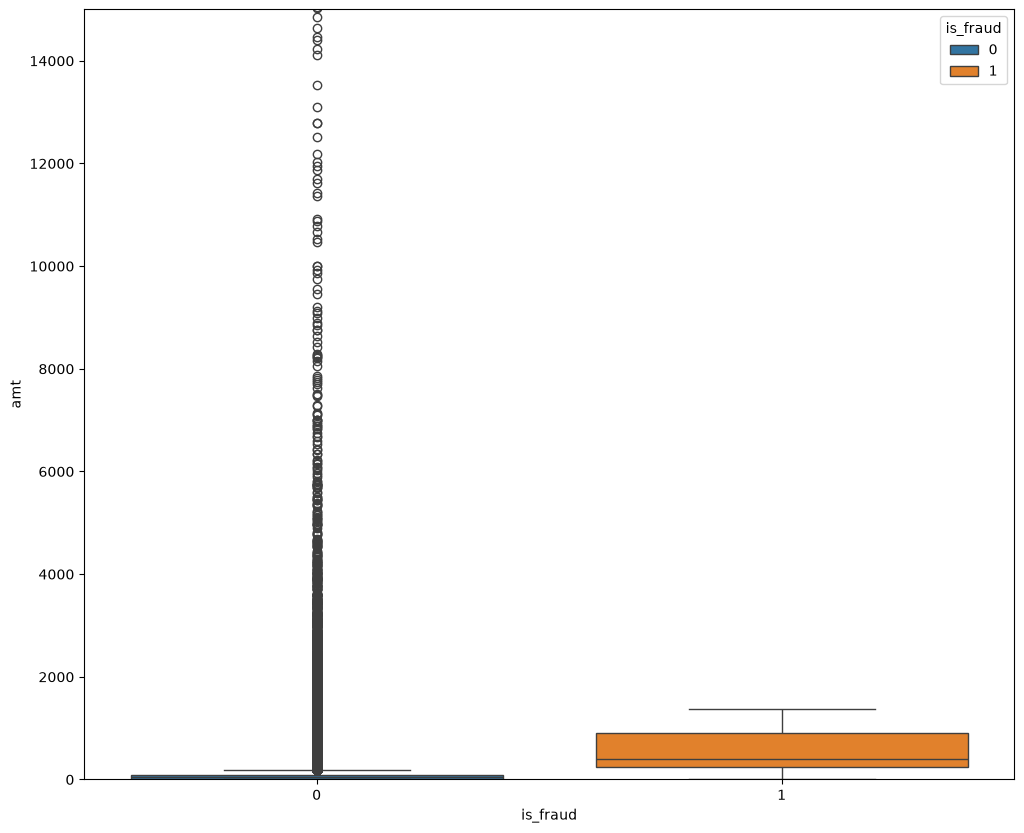

In [91]:
plt.figure(figsize = (12,10))

sns.boxplot(df, x = "is_fraud", y = "amt", hue = "is_fraud")

plt.ylim(0, 15000)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
 [Text(0, 0, 'misc_net'),
  Text(1, 0, 'grocery_pos'),
  Text(2, 0, 'entertainment'),
  Text(3, 0, 'gas_transport'),
  Text(4, 0, 'misc_pos'),
  Text(5, 0, 'grocery_net'),
  Text(6, 0, 'shopping_net'),
  Text(7, 0, 'shopping_pos'),
  Text(8, 0, 'food_dining'),
  Text(9, 0, 'personal_care'),
  Text(10, 0, 'health_fitness'),
  Text(11, 0, 'travel'),
  Text(12, 0, 'kids_pets'),
  Text(13, 0, 'home')])

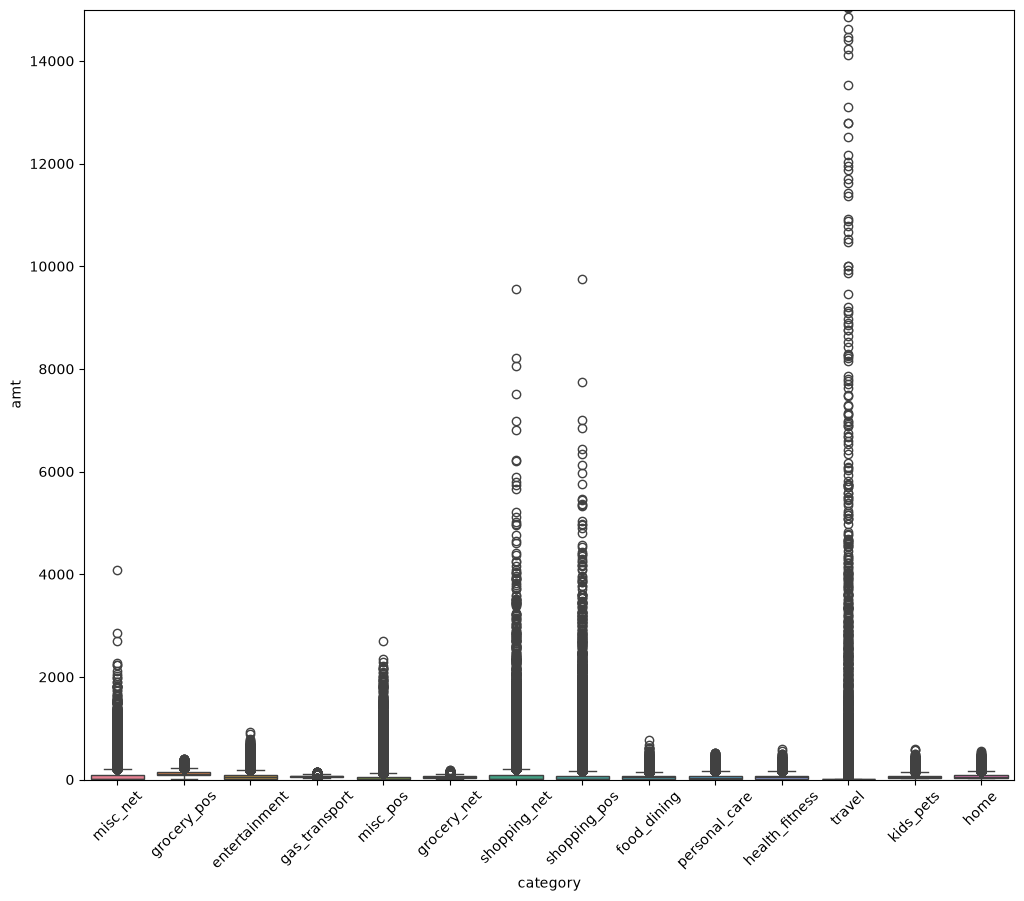

In [92]:
plt.figure(figsize = (12,10))

sns.boxplot(df, x = "category", y = "amt", hue = "category")
plt.ylim(0, 15000)
plt.xticks(rotation=45)

В датасете приличное количество выбросов в признаке amt, из за дисбаланса классов, значения выбросов сосредоточены в не мошеннически транзакциях. Судя пр графику 2 выбросов прилично в категориях travel и категриях shopping_net/pos (Аналог прочего, с нюансом pos - оффлайн покупка, net - онлайн покупка)